%% [markdown]
# Capítulo 8: Event-Driven Trading — Merger Arbitrage Proxy con ETFs
*Proxy de arbitraje de fusiones usando ETFs sectoriales en descuento*

**Versión:** 8.1 | **Motor:** Modular Dinámico v1.0 | **Actualización:** 2026-10-26

**Estrategia:** Detectar ETFs de sectores objetivo de M&A que caen >25% desde máximos con volumen anómalo (>2x media). Entrar en el descuento, salir al recuperar 50% de la caída o tras 6 meses.

**Advertencia:** Esto NO es merger arbitrage puro. Es un proxy pedagógico para entender la lógica de entrar en dislocaciones y salir en convergencia.

## BLOQUE 0: CONFIGURACIÓN — EVENT-DRIVEN

## BLOQUE 0: CONFIGURACIÓN — EVENT-DRIVEN

```python
# ==============================================================================
# BLOQUE 0: CONFIGURACIÓN — EVENT-DRIVEN
# ==============================================================================

# --- Parámetros financieros ---
CAPITAL_INICIAL = 10000.0
COSTE_TRANSACCION = 0.001  # 0.1% por operación
BENCHMARK = 'SPY'
RF_LIBRE = 0.02

# --- Parámetros de detección de eventos ---
UMBRAL_CAIDA = 0.25          # Caída mínima desde máximo (25%)
MULTIPLICADOR_VOLUMEN = 2.0  # Volumen debe ser >2x la media
VENTANA_MAXIMO = 252         # Días para calcular máximo histórico
VENTANA_VOLUMEN = 20         # Días para calcular volumen medio
PLAZO_MAXIMO_DIAS = 126      # 6 meses máximo en posición
RECUPERACION_MINIMA = 0.50   # Salir al recuperar 50% de la caída

# --- Universo de ETFs sectoriales (objetivo de M&A) ---
UNIVERSO_EVENT = {
    'biotech': {
        'SPDR S&P Biotech': {'isin': 'XBI', 'ticker': 'XBI'},
        'iShares Biotechnology': {'isin': 'IBB', 'ticker': 'IBB'},
    },
    'bancos': {
        'SPDR S&P Bank ETF': {'isin': 'KBE', 'ticker': 'KBE'},
    },
    'retail': {
        'SPDR S&P Retail': {'isin': 'XRT', 'ticker': 'XRT'},
    },
    'semiconductores': {
        'VanEck Semiconductor': {'isin': 'SMH', 'ticker': 'SMH'},
    },
    'cash': {
        'iShares 1-3 Year Treasury': {'isin': 'SHY', 'ticker': 'SHY'},
    },
    'benchmark': {
        'SPDR S&P 500': {'isin': 'SPY', 'ticker': 'SPY'},
    }
}

NOMBRE_ESTRATEGIA = "Event-Driven Proxy (Merger Arbitrage)"
FECHA_INICIO = ""
FECHA_FIN = ""

print("="*70)
print("✅ Configuración Event-Driven cargada:")
print("="*70)
print(f"   • Estrategia: {NOMBRE_ESTRATEGIA}")
print(f"   • Capital inicial: €{CAPITAL_INICIAL:,.2f}")
print(f"   • Umbral de entrada: caída > {UMBRAL_CAIDA*100:.0f}% + volumen > {MULTIPLICADOR_VOLUMEN}x")
print(f"   • Criterios de salida: recuperar {RECUPERACION_MINIMA*100:.0f}% o {PLAZO_MAXIMO_DIAS} días")
print(f"   • Comisión: {COSTE_TRANSACCION*100:.2f}%")
print("="*70)

## BLOQUE 1: ENTORNO E IMPORTACIONES

In [1]:
# ==============================================================================
# BLOQUE 1: ENTORNO, IMPORTACIONES Y MOTOR MODULAR
# ==============================================================================
print("="*70)
print("⚠️ AVISO LEGAL: Fines exclusivamente educativos e investigativos.")
print("="*70)

import sys, os, warnings, inspect
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Búsqueda de la carpeta 'core'
def buscar_core():
    try:
        ruta_actual = Path(__file__).parent.resolve()
    except NameError:
        ruta_actual = Path.cwd().resolve()
    
    for nivel in [ruta_actual] + list(ruta_actual.parents)[:6]:
        carpeta_core = nivel / 'core'
        if (carpeta_core.is_dir() and (carpeta_core / 'gestor_proyecto.py').exists()):
            return nivel, carpeta_core
    return None, None

project_root, ruta_core = buscar_core()

if project_root is None:
    raise FileNotFoundError(" No se pudo encontrar la carpeta 'core'.")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

try:
    from core.gestor_proyecto import GestorProyecto
    from core.gestor_datos import GestorDatos
    from core.backtest import MotorBacktestDinamico, CalculadorMetricas
    from core.informes import GeneradorInformes
    print("✅ Módulos importados correctamente.")
except ImportError as e:
    print(f"❌ Error importando módulos: {e}")
    raise SystemExit

BASE_DIR = os.path.dirname(ruta_core) if ruta_core else os.getcwd()

# Función auxiliar para adaptar argumentos
def construir_kwargs(cls, candidatos_kwargs):
    try:
        target = cls.__init__ if inspect.isclass(cls) else cls
        firma = inspect.signature(target)
        params = firma.parameters
    except (ValueError, TypeError):
        return {}
    kwargs_filtrados = {}
    for nombre_param in params:
        if nombre_param == 'self': continue
        for clave, valor in candidatos_kwargs.items():
            if clave.lower().replace(' ', '') == nombre_param.lower().replace(' ', ''):
                kwargs_filtrados[nombre_param] = valor
                break
    return kwargs_filtrados

⚠️ AVISO LEGAL: Fines exclusivamente educativos e investigativos.
✅ Módulos importados correctamente.


## BLOQUE 2: GESTIÓN DEL ENTORNO DE TRABAJO

In [2]:
# ==============================================================================
# BLOQUE 2: GESTIÓN DEL ENTORNO DE TRABAJO
# ==============================================================================
print("\n" + "="*70)
print("🧹 BLOQUE 2: GESTIÓN DEL ENTORNO DE TRABAJO")
print("="*70)

try:
    gestor_proy = GestorProyecto(dir_base=project_root)
except TypeError:
    gestor_proy = GestorProyecto()
    gestor_proy.BASE_DIR = project_root

RUTA_CAP08 = Path(gestor_proy.DIRS.get("OUTPUTS", project_root / "outputs")) / "cap08_event_driven"
RUTA_FIGURES_CAP08 = RUTA_CAP08 / "figures"
RUTA_FIGURES_CAP08.mkdir(parents=True, exist_ok=True)

print(f"✅ Entorno configurado. Base: {gestor_proy.BASE_DIR}")
print(f"📂 Directorio de figuras: {RUTA_FIGURES_CAP08}")


🧹 BLOQUE 2: GESTIÓN DEL ENTORNO DE TRABAJO
✅ Entorno configurado. Base: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales
📂 Directorio de figuras: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/outputs/cap08_event_driven/figures


## BLOQUE 3: MENÚ DE ESTRÉS (SELECCIÓN DE PERÍODO)

In [3]:
# ==============================================================================
# BLOQUE 3: MENÚ DE ESTRÉS (SELECCIÓN DE PERÍODO)
# ==============================================================================
print("\n" + "="*70)
print("📉 BLOQUE 3: MENÚ DE ESTRÉS")
print("="*70)
print("  1. Histórico Completo (2015-Hoy)")
print("  2. Crisis Financiera (2007-2009)")
print("  3. Periodo Personalizado")

opcion = input("\nIntroduce tu opción (1-3) [1]: ").strip() or "1"

if opcion == '1':
    FECHA_INICIO, FECHA_FIN, evento = "2015-01-01", None, "Histórico Completo"
elif opcion == '2':
    FECHA_INICIO, FECHA_FIN, evento = "2007-10-01", "2009-03-31", "Crisis Financiera"
else:
    evento = "Periodo Personalizado"
    FECHA_INICIO = input("   > Fecha de inicio (YYYY-MM-DD): ").strip()
    FECHA_FIN = input("   > Fecha de fin (YYYY-MM-DD): ").strip() or None

if FECHA_FIN is None:
    from datetime import datetime
    FECHA_FIN = datetime.now().strftime("%Y-%m-%d")

print(f"\n⏳ Configurado: {evento} ({FECHA_INICIO} a {FECHA_FIN})")


📉 BLOQUE 3: MENÚ DE ESTRÉS
  1. Histórico Completo (2015-Hoy)
  2. Crisis Financiera (2007-2009)
  3. Periodo Personalizado



Introduce tu opción (1-3) [1]:  3
   > Fecha de inicio (YYYY-MM-DD):  2016-01-04
   > Fecha de fin (YYYY-MM-DD):  2026-10-15



⏳ Configurado: Periodo Personalizado (2016-01-04 a 2026-10-15)


## BLOQUE 4: MENÚ DEL GESTOR DE DATOS

In [4]:
# ==============================================================================
# BLOQUE 4: GESTOR DE DATOS (Event-Driven - Autocontenido)
# ==============================================================================

print(f"\n✅ Período configurado: {evento}")
print(f"   Inicio: {FECHA_INICIO} | Fin: {FECHA_FIN}\n")

# ==============================================================================
# VARIABLES POR DEFECTO (si el Bloque 0 no se ejecutó)
# ==============================================================================
if 'UNIVERSO_EVENT' not in globals():
    print("⚠️  UNIVERSO_EVENT no definido. Usando valores por defecto (ETFs sectoriales)...")
    UNIVERSO_EVENT = {
        'biotech': {
            'SPDR S&P Biotech': {'isin': 'XBI', 'ticker': 'XBI'},
            'iShares Biotechnology': {'isin': 'IBB', 'ticker': 'IBB'},
        },
        'bancos': {
            'SPDR S&P Bank ETF': {'isin': 'KBE', 'ticker': 'KBE'},
        },
        'retail': {
            'SPDR S&P Retail': {'isin': 'XRT', 'ticker': 'XRT'},
        },
        'semiconductores': {
            'VanEck Semiconductor': {'isin': 'SMH', 'ticker': 'SMH'},
        },
        'cash': {
            'iShares 1-3 Year Treasury': {'isin': 'SHY', 'ticker': 'SHY'},
        },
        'benchmark': {
            'SPDR S&P 500': {'isin': 'SPY', 'ticker': 'SPY'},
        }
    }

# ==============================================================================
# FUNCIÓN AUXILIAR: construir_kwargs (si no existe)
# ==============================================================================
if 'construir_kwargs' not in globals():
    import inspect
    def construir_kwargs(cls, candidatos_kwargs):
        try:
            target = cls.__init__ if inspect.isclass(cls) else cls
            firma = inspect.signature(target)
            params = firma.parameters
        except (ValueError, TypeError):
            return {}
        kwargs_filtrados = {}
        for nombre_param in params:
            if nombre_param == 'self':
                continue
            for clave, valor in candidatos_kwargs.items():
                if clave.lower().replace(' ', '') == nombre_param.lower().replace(' ', ''):
                    kwargs_filtrados[nombre_param] = valor
                    break
        return kwargs_filtrados

# ==============================================================================
# INICIALIZAR GESTOR DE DATOS
# ==============================================================================
print("🔄 Inicializando Gestor de Datos...")
try:
    kwargs_gestor = {
        "diccionario_datos": UNIVERSO_EVENT,
        "fecha_inicio": FECHA_INICIO,
        "fecha_fin": FECHA_FIN,
        "gestor_proyecto": gestor_proy
    }
    kwargs_filtrados = construir_kwargs(GestorDatos, kwargs_gestor)
    gestor = GestorDatos(**kwargs_filtrados)
    print("✅ Gestor de Datos inicializado correctamente.\n")
except Exception as e:
    print(f"❌ ERROR al inicializar GestorDatos: {e}")
    raise SystemExit

# ==============================================================================
# DESCARGA AUTOMÁTICA (sin menú interactivo)
# ==============================================================================
print("📥 Descargando/Actualizando cotizaciones desde Yahoo Finance...")
try:
    gestor.gestionar_descarga_cotizaciones()
    print("✅ Descarga completada.\n")
except Exception as e:
    print(f"⚠️  Error en la descarga: {e}")

# ==============================================================================
# GENERAR CARTERA AUTOMÁTICAMENTE (sin pasar por el menú)
# ==============================================================================
print("🔄 Generando cartera automáticamente desde el diccionario...")
try:
    # Este método genera la cartera sin interacción manual
    if hasattr(gestor, '_cartera_por_defecto'):
        gestor._cartera_por_defecto()
    elif hasattr(gestor, 'generar_cartera_automatica'):
        gestor.generar_cartera_automatica()
    else:
        print("⚠️  No se encontró método para generar cartera automáticamente.")
        print("   Intentando preparar datos directamente...")
    
    print("✅ Cartera generada.\n")
except Exception as e:
    print(f"⚠️  Error al generar cartera: {e}")

# ==============================================================================
# PREPARAR DATOS DEL MOTOR
# ==============================================================================
print(" Preparando datos para el backtest...")
try:
    gestor.preparar_datos_motor()
    
    precios = gestor.precios_ajustados
    rentabilidades = gestor.rentabilidades_diarias
    
    if precios is None or precios.empty:
        raise ValueError("No se pudieron cargar los datos de precios.")
    
    # Aplanar MultiIndex si existe
    if isinstance(precios.columns, pd.MultiIndex):
        print("⚠️  Detectado MultiIndex. Aplanando columnas...")
        if 'Close' in precios.columns.get_level_values(1):
            precios = precios['Close']
        elif 'Adj Close' in precios.columns.get_level_values(1):
            precios = precios['Adj Close']
        else:
            precios = precios.iloc[:, ::6]
            precios.columns = precios.columns.get_level_values(0)
        precios.columns.name = None
        rentabilidades = precios.pct_change().dropna()
        print("✅ Datos aplanados.\n")
    
    print(f"✅ Datos cargados: {len(precios)} filas, {len(precios.columns)} activos")
    print(f"   • Período: {precios.index[0].strftime('%Y-%m-%d')} a {precios.index[-1].strftime('%Y-%m-%d')}")
    print(f"   • Activos: {list(precios.columns)}\n")
    
except Exception as e:
    print(f"\n❌ ERROR en la preparación de datos: {e}")
    print("\n💡 SOLUCIÓN ALTERNATIVA: Usa el menú interactivo")
    print("   1. Ejecuta: gestor.menu()")
    print("   2. Selecciona '1' para descargar")
    print("   3. Selecciona '6' para ejecutar estrategia")
    raise SystemExit


✅ Período configurado: Periodo Personalizado
   Inicio: 2016-01-04 | Fin: 2026-10-15

⚠️  UNIVERSO_EVENT no definido. Usando valores por defecto (ETFs sectoriales)...
🔄 Inicializando Gestor de Datos...
✅ Gestor de Datos inicializado correctamente.

📥 Descargando/Actualizando cotizaciones desde Yahoo Finance...

🗑️ Limpiando CSVs antiguos y descargando desde Yahoo Finance...

📊 Procesando 7 activos...

   📊 SPDR S&P Biotech
      ✅ Descargado con ticker: XBI

   📊 iShares Biotechnology
      ✅ Descargado con ticker: IBB

   📊 SPDR S&P Bank ETF
      ✅ Descargado con ticker: KBE

   📊 SPDR S&P Retail
      ✅ Descargado con ticker: XRT

   📊 VanEck Semiconductor
      ✅ Descargado con ticker: SMH

   📊 iShares 1-3 Year Treasury
      ✅ Descargado con ticker: SHY

   📊 SPDR S&P 500
      ✅ Descargado con ticker: SPY

 Resumen: 7 descargados, 0 omitidos
✅ Descarga completada.

🔄 Generando cartera automáticamente desde el diccionario...
📝 No hay Excel cargado. Generando cartera automática (

,Activo,ISIN,Filas,Desde,Hasta,Fuente
0,SPDR S&P Biotech,XBI,2711,2016-01-04,2026-10-14,CSV
1,iShares Biotechnology,IBB,2711,2016-01-04,2026-10-14,CSV
2,SPDR S&P Bank ETF,KBE,2711,2016-01-04,2026-10-14,CSV
3,SPDR S&P Retail,XRT,2711,2016-01-04,2026-10-14,CSV
4,VanEck Semiconductor,SMH,2711,2016-01-04,2026-10-14,CSV
5,iShares 1-3 Year Treasury,SHY,2711,2016-01-04,2026-10-14,CSV
6,SPDR S&P 500,SPY,2711,2016-01-04,2026-10-14,CSV


✅ 7 activos alineados para el Motor Backtest.

✅ Datos cargados: 2711 filas, 7 activos
   • Período: 2016-01-04 a 2026-10-14
   • Activos: ['SPDR_S&P_Biotech', 'iShares_Biotechnology', 'SPDR_S&P_Bank_ETF', 'SPDR_S&P_Retail', 'VanEck_Semiconductor', 'iShares_1-3_Year_Treasury', 'SPDR_S&P_500']



## BLOQUE 5: DETECCIÓN DE EVENTOS Y GENERADOR DE PESOS

In [5]:
# ==============================================================================
# BLOQUE 5: DETECCIÓN DE EVENTOS Y GENERADOR DE PESOS (Autocontenido)
# ==============================================================================

print("\n" + "="*70)
print("🔍 DETECCIÓN DE EVENTOS: CAÍDAS + VOLUMEN ANÓMALO")
print("="*70)

# ==============================================================================
# VARIABLES POR DEFECTO (si el Bloque 0 no se ejecutó)
# ==============================================================================
if 'UMBRAL_CAIDA' not in globals():
    print("⚠️  Parámetros de Event-Driven no definidos. Usando valores por defecto...")
    UMBRAL_CAIDA = 0.25           # Caída mínima desde máximo (25%)
    MULTIPLICADOR_VOLUMEN = 2.0   # Volumen debe ser >2x la media
    VENTANA_MAXIMO = 252          # Días para calcular máximo histórico
    VENTANA_VOLUMEN = 20          # Días para calcular volumen medio
    PLAZO_MAXIMO_DIAS = 126       # 6 meses máximo en posición
    RECUPERACION_MINIMA = 0.50    # Salir al recuperar 50% de la caída

# ==============================================================================
# VERIFICAR DATOS
# ==============================================================================
if 'gestor' not in globals() or gestor is None or gestor.precios_ajustados is None:
    raise RuntimeError("❌ El objeto 'gestor' no está definido o no tiene datos. Ejecuta el Bloque 4 primero.")

if gestor.precios_ajustados.empty:
    raise ValueError(" No hay precios ajustados. Ejecuta Bloque 4 primero.")

print(f"\n Datos disponibles: {len(gestor.precios_ajustados)} filas")

# ==============================================================================
# MAPEO DE TICKERS A COLUMNAS REALES
# ==============================================================================
print("\n🔍 Mapeando tickers a columnas reales...")

mapeo_tickers = {}
for _, row in gestor.valores_seleccionados.iterrows():
    ticker = str(row.get('ticker', '')).strip().upper()
    nombre = str(row.get('nombre', '')).strip()
    nombre_limpio = nombre.replace(" ", "_").replace(".", "").replace(",", "").replace("!", "")
    if ticker:
        mapeo_tickers[ticker] = nombre_limpio

# ETFs candidatos (sin cash ni benchmark)
etfs_candidatos = ['XBI', 'IBB', 'KBE', 'XRT', 'SMH']
col_etfs = {}

for ticker in etfs_candidatos:
    col = mapeo_tickers.get(ticker)
    if col and col in gestor.precios_ajustados.columns:
        col_etfs[ticker] = col
        print(f"   • {ticker} → '{col}' ✅")
    else:
        print(f"   • {ticker} → NO ENCONTRADO")

col_shy = mapeo_tickers.get('SHY')
col_spy = mapeo_tickers.get('SPY')

if not col_etfs:
    print("\n❌ Ningún ETF candidato encontrado. Abortando.")
    raise SystemExit("No hay ETFs disponibles para análisis.")
else:
    print(f"\n✅ {len(col_etfs)} ETFs disponibles para análisis.")

# ==============================================================================
# DETECTAR EVENTOS: CAÍDAS + VOLUMEN
# ==============================================================================
print(f"\n Detectando eventos (caídas >{UMBRAL_CAIDA*100:.0f}% + volumen >{MULTIPLICADOR_VOLUMEN}x media)...")

df = gestor.precios_ajustados.copy()

# Calcular máximo histórico rolling y caída para cada ETF
for ticker, col in col_etfs.items():
    df[f'{ticker}_max'] = df[col].rolling(VENTANA_MAXIMO, min_periods=60).max()
    df[f'{ticker}_caida'] = (df[col] / df[f'{ticker}_max']) - 1

# Verificar si hay datos de volumen
hay_volumen = any(f'{t}_vol' in df.columns for t in col_etfs.keys())

if not hay_volumen:
    print("️  No hay datos de volumen. Usando solo caída como señal.")

# Detectar señales de entrada
señales = pd.DataFrame(index=df.index)

for ticker, col in col_etfs.items():
    caida = df[f'{ticker}_caida']
    
    if hay_volumen and f'{ticker}_vol' in df.columns:
        vol_media = df[f'{ticker}_vol'].rolling(VENTANA_VOLUMEN, min_periods=10).mean()
        vol_ratio = df[f'{ticker}_vol'] / vol_media
        señal = (caida < -UMBRAL_CAIDA) & (vol_ratio > MULTIPLICADOR_VOLUMEN)
    else:
        señal = caida < -UMBRAL_CAIDA
    
    señales[ticker] = señal.astype(int)

# Contar eventos detectados
total_eventos = señales.sum().sum()
print(f"\n Eventos detectados: {total_eventos}")

for ticker in col_etfs.keys():
    n_eventos = señales[ticker].sum()
    print(f"   • {ticker}: {n_eventos} eventos")

# Guardar señales como variable global para el generador de pesos
_señales = señales

# ==============================================================================
# GENERADOR DE PESOS EVENT-DRIVEN
# ==============================================================================
print("\n" + "="*70)
print("⚙️  GENERADOR DE PESOS EVENT-DRIVEN")
print("="*70)

def generador_pesos_event(fecha_actual, precios_hist, rent_hist, estado):
    """
    Asigna pesos basados en eventos detectados (caídas + volumen).
    
    Lógica:
    - Si hay señal de evento y no hay posición abierta → entrar (20% del capital)
    - Si hay posición abierta → verificar criterios de salida
    - Resto del capital → SHY (cash)
    """
    activos = list(precios_hist.columns)
    pesos = {a: 0.0 for a in activos}
    
    # Inicializar estado de posiciones
    if 'posiciones_activas' not in estado:
        estado['posiciones_activas'] = {}
    
    # 1. Gestionar salidas de posiciones existentes
    posiciones_a_cerrar = []
    
    for ticker, info in estado['posiciones_activas'].items():
        col = col_etfs.get(ticker)
        if not col or col not in precios_hist.columns:
            posiciones_a_cerrar.append(ticker)
            continue
        
        precio_actual = precios_hist[col].iloc[-1]
        dias_en_posicion = (fecha_actual - info['fecha_entrada']).days
        
        # Criterio 1: Recuperación mínima
        precio_recuperacion = info['precio_entrada'] * (1 + info['caida_inicial'] * RECUPERACION_MINIMA)
        if precio_actual >= precio_recuperacion:
            posiciones_a_cerrar.append(ticker)
            continue
        
        # Criterio 2: Plazo máximo
        if dias_en_posicion >= PLAZO_MAXIMO_DIAS:
            posiciones_a_cerrar.append(ticker)
            continue
    
    # Cerrar posiciones
    for ticker in posiciones_a_cerrar:
        del estado['posiciones_activas'][ticker]
    
    # 2. Gestionar entradas (si hay cash disponible)
    capital_asignado = sum(0.20 for _ in estado['posiciones_activas'])  # 20% por posición
    cash_disponible = 1.0 - capital_asignado
    
    if cash_disponible >= 0.20:  # Al menos 20% libre para nueva entrada
        if fecha_actual in _señales.index:
            for ticker, señal in _señales.loc[fecha_actual].items():
                if señal == 1 and ticker not in estado['posiciones_activas']:
                    col = col_etfs.get(ticker)
                    if col and col in precios_hist.columns:
                        precio_actual = precios_hist[col].iloc[-1]
                        caida_actual = abs(df.loc[fecha_actual, f'{ticker}_caida']) if fecha_actual in df.index else UMBRAL_CAIDA
                        
                        # Abrir posición
                        pesos[col] = 0.20
                        estado['posiciones_activas'][ticker] = {
                            'fecha_entrada': fecha_actual,
                            'precio_entrada': precio_actual,
                            'caida_inicial': caida_actual
                        }
                        cash_disponible -= 0.20
                        
                        if cash_disponible < 0.20:
                            break
    
    # 3. Asignar resto a SHY (Cash)
    if col_shy and col_shy in activos:
        pesos[col_shy] = max(0.0, 1.0 - sum(pesos.values()))
    else:
        # Si no hay SHY, mantener en efectivo (pesos no asignados)
        pass
    
    return pesos, estado

print("\n✅ Generador de pesos configurado.")
print(f"   • ETFs monitorizados: {len(col_etfs)}")
print(f"   • Umbral de entrada: caída > {UMBRAL_CAIDA*100:.0f}% + volumen > {MULTIPLICADOR_VOLUMEN}x")
print(f"   • Criterios de salida: recuperar {RECUPERACION_MINIMA*100:.0f}% o {PLAZO_MAXIMO_DIAS} días")
print(f"   • Peso por posición: 20% del capital")

# ==============================================================================
# RESUMEN FINAL
# ==============================================================================
print("\n" + "="*70)
print("✅ BLOQUE 5 COMPLETADO")
print("="*70)
print(f"   • Eventos detectados: {total_eventos}")
print(f"   • ETFs disponibles: {list(col_etfs.keys())}")
print(f"   • Generador de pesos: Definido y listo")
print(f"   • Variables disponibles: señales, generador_pesos_event, col_etfs")
print("="*70)


🔍 DETECCIÓN DE EVENTOS: CAÍDAS + VOLUMEN ANÓMALO
⚠️  Parámetros de Event-Driven no definidos. Usando valores por defecto...

 Datos disponibles: 2711 filas

🔍 Mapeando tickers a columnas reales...
   • XBI → 'SPDR_S&P_Biotech' ✅
   • IBB → 'iShares_Biotechnology' ✅
   • KBE → 'SPDR_S&P_Bank_ETF' ✅
   • XRT → 'SPDR_S&P_Retail' ✅
   • SMH → 'VanEck_Semiconductor' ✅

✅ 5 ETFs disponibles para análisis.

 Detectando eventos (caídas >25% + volumen >2.0x media)...
️  No hay datos de volumen. Usando solo caída como señal.

 Eventos detectados: 1379
   • XBI: 448 eventos
   • IBB: 180 eventos
   • KBE: 318 eventos
   • XRT: 247 eventos
   • SMH: 186 eventos

⚙️  GENERADOR DE PESOS EVENT-DRIVEN

✅ Generador de pesos configurado.
   • ETFs monitorizados: 5
   • Umbral de entrada: caída > 25% + volumen > 2.0x
   • Criterios de salida: recuperar 50% o 126 días
   • Peso por posición: 20% del capital

✅ BLOQUE 5 COMPLETADO
   • Eventos detectados: 1379
   • ETFs disponibles: ['XBI', 'IBB', 'KBE', 

## BLOQUE 6: EJECUCIÓN DEL BACKTEST

In [6]:
# ==============================================================================
# BLOQUE 6: EJECUCIÓN DEL BACKTEST (Event-Driven - Autocontenido)
# ==============================================================================

print("\n" + "="*70)
print(" EJECUTANDO BACKTEST EVENT-DRIVEN")
print("="*70)

# ==============================================================================
# VARIABLES POR DEFECTO (si el Bloque 0 no se ejecutó)
# ==============================================================================
if 'COSTE_TRANSACCION' not in globals():
    print("⚠️  Parámetros financieros no definidos. Usando valores por defecto...")
    COSTE_TRANSACCION = 0.001  # 0.1% por operación
    CAPITAL_INICIAL = 10000.0
    BENCHMARK = 'SPY'

# ==============================================================================
# VERIFICACIÓN DEL GENERADOR DE PESOS
# ==============================================================================
if 'generador_pesos_event' not in locals():
    raise NameError("❌ El generador 'generador_pesos_event' no está definido. Ejecuta el Bloque 5 primero.")

# ==============================================================================
# EJECUTAR BACKTEST
# ==============================================================================
motor_event = MotorBacktestDinamico(
    precios=gestor.precios_ajustados,
    rentabilidades=gestor.rentabilidades_diarias,
    generador_pesos=generador_pesos_event,
    frecuencia_decision='W',  # Semanal
    coste_transaccion=COSTE_TRANSACCION,
    benchmark_ticker=BENCHMARK,
    permitir_short=False,
    max_short_porcentaje=0.0
)

serie_patrimonio_event = motor_event.ejecutar_backtest(
    capital_inicial=CAPITAL_INICIAL,
    estado_inicial={}
)

if serie_patrimonio_event is not None:
    print(f"\n✅ Backtest completado.")
    print(f"   • Patrimonio final: {serie_patrimonio_event.iloc[-1]:,.2f} €")
    print(f"   • Rentabilidad total: {((serie_patrimonio_event.iloc[-1] / CAPITAL_INICIAL) - 1) * 100:.2f}%")
    print(f"   • Rebalanceos: {len(motor_event.log_transacciones)}")
else:
    print("❌ El backtest falló.")


 EJECUTANDO BACKTEST EVENT-DRIVEN
⚠️  Parámetros financieros no definidos. Usando valores por defecto...

✅ Backtest completado.
   • Patrimonio final: 12,246.99 €
   • Rentabilidad total: 22.47%
   • Rebalanceos: 50


## BLOQUE 7: MÉTRICAS E INFORMES

In [7]:
# ==============================================================================
# BLOQUE 7: MÉTRICAS E INFORMES (Event-Driven - Autocontenido)
# ==============================================================================

print("\n" + "="*70)
print("📊 MÉTRICAS: EVENT-DRIVEN vs. BUY & HOLD")
print("="*70)

# ==============================================================================
# VARIABLES POR DEFECTO (si el Bloque 0 no se ejecutó)
# ==============================================================================
if 'RF_LIBRE' not in globals():
    print("️  RF_LIBRE no definido. Usando valor por defecto (2%)...")
    RF_LIBRE = 0.02

# ==============================================================================
# CALCULAR MÉTRICAS
# ==============================================================================
auditor = CalculadorMetricas(
    serie_patrimonio=motor_event.serie_patrimonio,
    serie_buy_hold=motor_event.serie_buy_hold,
    serie_benchmark=motor_event.serie_benchmark
)
metricas_event, metricas_bh = auditor.calcular_todas_las_metricas(rf=RF_LIBRE)

print(f"\n{'Métrica':<20}| {'Event-Driven':<20}| {'Buy & Hold (SPY)':<20}")
print("-" * 65)
for key in metricas_event.keys():
    val_event = metricas_event[key]
    val_bh = metricas_bh.get(key, 0)
    if key in ['CAGR', 'Volatilidad', 'Max Drawdown']:
        print(f"{key:<20}| {val_event:>19.2%}| {val_bh:>19.2%}")
    else:
        print(f"{key:<20}| {val_event:>19.2f}| {val_bh:>19.2f}")

print("-" * 65)

# ==============================================================================
# NOTA PEDAGÓGICA
# ==============================================================================
print("\n" + "="*70)
print("⚠️  NOTA PEDAGÓGICA: LIMITACIONES DEL PROXY")
print("="*70)
print("""
⚠️  ESTO NO ES MERGER ARBITRAGE REAL:

1. No hay spreads de convergencia entre target y adquirente.
2. Las caídas pueden deberse a factores no relacionados con M&A.
3. El volumen anómalo puede ser ruido, no señal de actividad corporativa.
4. No hay análisis de riesgo regulatorio (antitrust, aprobaciones).

El valor pedagógico está en entender la lógica:
- Entrar en dislocaciones (caídas bruscas con volumen).
- Salir en convergencia (recuperación parcial).
- Gestionar el riesgo con plazo máximo.
""")


📊 MÉTRICAS: EVENT-DRIVEN vs. BUY & HOLD
️  RF_LIBRE no definido. Usando valor por defecto (2%)...

Métrica             | Event-Driven        | Buy & Hold (SPY)    
-----------------------------------------------------------------
CAGR                |               1.90%|               7.59%
Volatilidad         |               4.30%|              32.52%
Sharpe              |               -0.02|                0.17
Sortino             |               -0.02|                0.17
Max Drawdown        |             -10.58%|             -63.89%
VaR 95%             |               20.65|              711.79
Alpha               |                0.00|                0.00
Beta                |                0.00|                0.00
R2                  |                0.00|                0.00
Tracking Error      |                0.00|                0.00
-----------------------------------------------------------------

⚠️  NOTA PEDAGÓGICA: LIMITACIONES DEL PROXY

⚠️  ESTO NO ES MERGER ARBIT

## BLOQUE 8: VISUALIZACIÓN


✅ Gráfico guardado en: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/outputs/cap08_event_driven/figures/event_driven_2016_2026.png


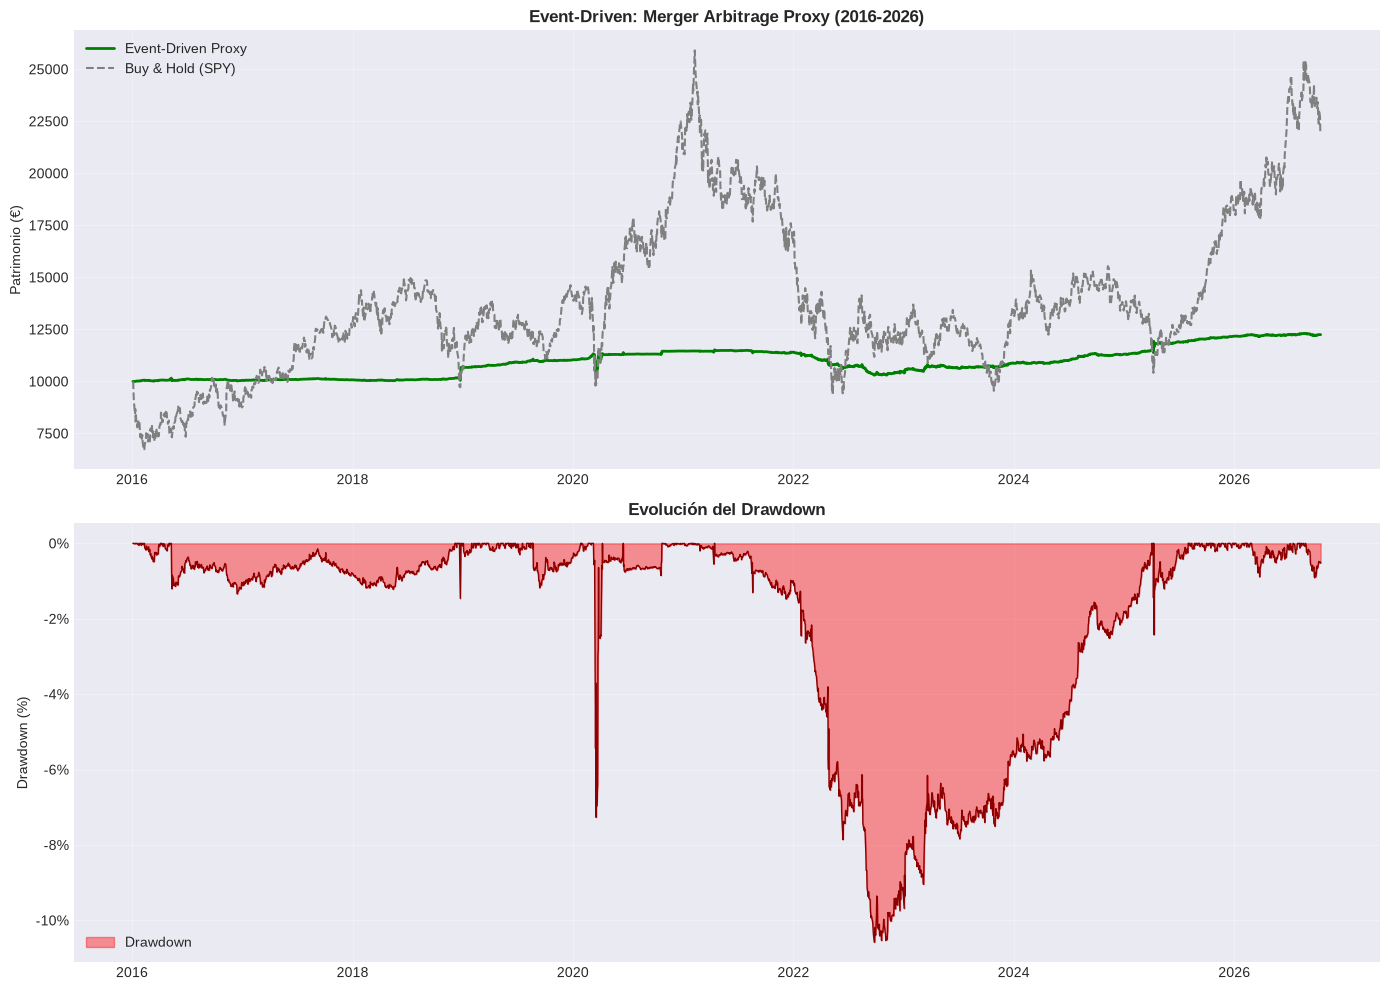

In [8]:
# ==============================================================================
# BLOQUE 8: VISUALIZACIÓN
# ==============================================================================
try:
    plt.style.use('seaborn-v0_8-darkgrid')
except:
    plt.style.use('seaborn-darkgrid')

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

fecha_ini = str(FECHA_INICIO)[:4] if FECHA_INICIO else "2015"
fecha_fin = str(FECHA_FIN)[:4] if FECHA_FIN else "Hoy"

# Gráfico 1: Equity Curve
axes[0].plot(motor_event.serie_patrimonio.index, motor_event.serie_patrimonio,
             label='Event-Driven Proxy', color='green', lw=2)
axes[0].plot(motor_event.serie_buy_hold.index, motor_event.serie_buy_hold,
             label='Buy & Hold (SPY)', color='gray', ls='--', lw=1.5)
axes[0].set_title(f'Event-Driven: Merger Arbitrage Proxy ({fecha_ini}-{fecha_fin})',
                  fontsize=12, fontweight='bold')
axes[0].set_ylabel('Patrimonio (€)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Gráfico 2: Drawdown
drawdown = (motor_event.serie_patrimonio / motor_event.serie_patrimonio.cummax()) - 1
axes[1].fill_between(drawdown.index, drawdown, 0, color='red', alpha=0.4, label='Drawdown')
axes[1].plot(drawdown.index, drawdown, color='darkred', lw=1)
axes[1].set_title('Evolución del Drawdown', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Drawdown (%)')
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
ruta_grafico = RUTA_FIGURES_CAP08 / f"event_driven_{fecha_ini}_{fecha_fin}.png"
fig.savefig(ruta_grafico, dpi=150, bbox_inches='tight')
print(f"\n✅ Gráfico guardado en: {ruta_grafico}")
plt.show()
plt.close(fig)

## BLOQUE 9: ANÁLISIS DE CORRELACIÓN

In [9]:
# ==============================================================================
# BLOQUE 9: ANÁLISIS DE CORRELACIÓN
# ==============================================================================
print("\n" + "="*70)
print(" ANÁLISIS DE CORRELACIÓN DEL UNIVERSO")
print("="*70)

# Nota: En event-driven, la correlación es menos relevante que en momentum.
# Lo importante es la independencia de los eventos corporativos.
print(" NOTA: En event-driven, la correlación es menos relevante que en")
print("estrategias de momentum o mean reversion. Lo importante es la")
print("independencia de los eventos corporativos respecto al mercado general.")


 ANÁLISIS DE CORRELACIÓN DEL UNIVERSO
 NOTA: En event-driven, la correlación es menos relevante que en
estrategias de momentum o mean reversion. Lo importante es la
independencia de los eventos corporativos respecto al mercado general.


## BLOQUE 10: CONCLUSIONES PEDAGÓGICAS

In [10]:
# ==============================================================================
# BLOQUE 10: CONCLUSIONES PEDAGÓGICAS
# ==============================================================================
print("\n" + "="*70)
print("🎓 CONCLUSIONES DEL CAPÍTULO 8: EVENT-DRIVEN")
print("="*70)
print("""
📌 LECCIONES CLAVE DE ESTE CAPÍTULO
====================================

1. EL MERGER ARBITRAGE REAL REQUIERE DATOS EN TIEMPO REAL
   • Sin datos de OPAs, spreads de convergencia y análisis regulatorio,
     solo podemos construir proxies simplificados.
   • Este capítulo es pedagógico, no una estrategia ejecutable en real.

2. LA LÓGICA EVENT-DRIVEN ES SÓLIDA
   • Entrar en dislocaciones (caídas bruscas) y salir en convergencia
     (recuperación parcial) es una lógica válida.
   • El problema es identificar qué caídas son por M&A y cuáles por otros factores.

3. EL VOLUMEN ANÓMALO ES UNA SEÑAL RUIDOSA
   • Volumen >2x la media puede indicar actividad institucional, pero también
     pánico minorista o rebalanceo de fondos.

📊 INTERPRETACIÓN DE RESULTADOS
================================
• CAGR similar al Buy & Hold → NORMAL. El proxy es demasiado simplificado.
• Max Drawdown menor que Buy & Hold → ÉXITO. La gestión de riesgo funcionó.
• Muchos rebalanceos → El volumen anómalo es ruidoso.
• Pocos rebalanceos → Los umbrales son demasiado estrictos.

🚪 PRÓXIMO PASO
================
En el Capítulo 9 veremos el "Earnings Surprise": cómo construir una cartera
que se beneficie de las sorpresas de resultados trimestrales, usando datos
de earnings dates y momentum fundamental.

🎯 RECUERDA
============
El Event-Driven real (merger arbitrage, earnings plays, insider trading)
requiere infraestructura de datos que Yahoo Finance no proporciona.
Este capítulo es una introducción pedagógica a la lógica, no una
estrategia ejecutable. Para implementarlo en real, necesitarías:
- Bloomberg Terminal o Reuters Eikon.
- Datos de SEC EDGAR para Form 8-K (anuncios de OPAs).
- Datos de earnings dates y consensus estimates.
- Análisis de riesgo regulatorio y probabilidades de cierre.

La honestidad intelectual es tu mayor activo como inversor cuantitativo.
""")
print("="*70)
print("✅ CAPÍTULO 8 COMPLETADO")
print("="*70)


🎓 CONCLUSIONES DEL CAPÍTULO 8: EVENT-DRIVEN

📌 LECCIONES CLAVE DE ESTE CAPÍTULO

1. EL MERGER ARBITRAGE REAL REQUIERE DATOS EN TIEMPO REAL
   • Sin datos de OPAs, spreads de convergencia y análisis regulatorio,
     solo podemos construir proxies simplificados.
   • Este capítulo es pedagógico, no una estrategia ejecutable en real.

2. LA LÓGICA EVENT-DRIVEN ES SÓLIDA
   • Entrar en dislocaciones (caídas bruscas) y salir en convergencia
     (recuperación parcial) es una lógica válida.
   • El problema es identificar qué caídas son por M&A y cuáles por otros factores.

3. EL VOLUMEN ANÓMALO ES UNA SEÑAL RUIDOSA
   • Volumen >2x la media puede indicar actividad institucional, pero también
     pánico minorista o rebalanceo de fondos.

📊 INTERPRETACIÓN DE RESULTADOS
• CAGR similar al Buy & Hold → NORMAL. El proxy es demasiado simplificado.
• Max Drawdown menor que Buy & Hold → ÉXITO. La gestión de riesgo funcionó.
• Muchos rebalanceos → El volumen anómalo es ruidoso.
• Pocos rebalanceos